In [12]:
from tqdm import tqdm
from req_functions_from_ApproxSP import *
from generate_profiles import *
from mallows import *
import json
from impartial import *
import pandas as pd
from euclidean import *


In [2]:
def generate_MA(num_agents):
    votes_left = []
    votes_right = []

    for i in range(num_agents):
        row_left = [(i + j) % num_agents for j in range(num_agents)]
        votes_left.append(row_left)

        row_right = [(i - j) % num_agents for j in range(num_agents)]
        votes_right.append(row_right)

    return votes_left, votes_right


In [3]:
def generate_mallows_MA_votes(num_agents, phi_m, phi_w, **kwargs):
    """ Mallows on top of Asymmetric instance """
    
    votes_left_array, votes_right_array = generate_MA(num_agents)
    
    # Apply Mallows
    votes_left_array = mallows_votes(votes_left_array, phi_m)
    votes_right_array = mallows_votes(votes_right_array, phi_w)
    
    # No need for .tolist()
    votes_left = votes_left_array
    votes_right = votes_right_array

 
    j = 0
    for row in votes_left:
        for i in range(len(row)):
            votes_left[j][i] += 1
        j+=1
    j = 0
    for row in votes_right:
        for i in range(len(row)):
            votes_right[j][i] += 1
        j += 1
 
 
    return [votes_left, votes_right]

In [4]:

def mallows_vote(vote, phi):
    num_candidates = len(vote)
    raw_vote = generate_mallows_votes(1, num_candidates, phi=phi, weight=0)[0]
    new_vote = [0] * len(vote)
    for i in range(num_candidates):
        new_vote[raw_vote[i]] = vote[i]
    return new_vote
 
 
def mallows_votes(votes, phi):
    for i in range(len(votes)):
        votes[i] = mallows_vote(votes[i], phi)
    return votes
 
def generate_mallows_votes(num_voters, num_candidates, phi=0.5, weight=0, **kwargs):
    if phi is None:
        logging.warning('phi is not defined')
    insertion_probabilites_list = []
    for i in range(1, num_candidates):
        insertion_probabilites_list.append(computeInsertionProbas(i, phi))
    V = []
    for i in range(num_voters):
        vote = mallowsVote(num_candidates, insertion_probabilites_list)
        if weight > 0:
            probability = np.random.random()
            if probability <= weight:
                vote.reverse()
        V += [vote]
    return V
 

def computeInsertionProbas(i, phi):
    probas = (i + 1) * [0]
    for j in range(i + 1):
        probas[j] = pow(phi, (i + 1) - (j + 1))
    return probas


def mallowsVote(m, insertion_probabilites_list):
    vote = [0]
    for i in range(1, m):
        index = weighted_choice(insertion_probabilites_list[i - 1])
        vote.insert(index, i)
    return vote


def weighted_choice(choices):
    total = 0
    for w in choices:
        total = total + w
    r = np.random.uniform(0, total)
    upto = 0.0
    for i, w in enumerate(choices):
        if upto + w >= r:
            return i
        upto = upto + w
    assert False, "Shouldn'process_id get here"

**Self Manipulation**

In [9]:
data_mallows_MA_gain = []
n=10
phi_list=[0.0, 0.2, 0.4, 0.6, 0.8, 1.0]
 
for phi1 in phi_list:
    number_phi = []
 
    for phi2 in phi_list:
        count =[]
        ct=[]
 
        for samples in range (100):
            cnt=0
            pref = generate_mallows_MA_votes(n, phi1, phi2)
            mpref = pref[0]
            wpref = pref[1]
            #print(mpref)
            preferences = [mpref, wpref]
            benefit_women = []
            manipulated_matchings = []
            original_matchings = []
            manipulated_preferences = []
 
            for manipulator in range (1, n+1):
                matching = gale_shapley(mpref, wpref)
                result = self_manipulation(mpref, wpref, manipulator)
                matching2 = result[0]
                rk1 = 1000
                rk2 = 1000
 
                for i in range(0,n):
                    if matching[i] == manipulator:
                        partner1=i+1
                    if matching2[i] == manipulator:
                        partner2=i+1
                w_pref = wpref[manipulator-1]
                
                for i in range(0,n):
                    if w_pref[i] == partner1:
                        rk1=i
                    if w_pref[i] == partner2:
                        rk2=i
                manipulated_matchings.append(matching2)
                original_matchings.append(matching)
                manipulated_preferences.append(result[1])
                benefit = abs(rk1-rk2)
                benefit_women.append(benefit)
            data_mallows_MA_gain.append([phi1, phi2, preferences, samples, manipulated_preferences, original_matchings, manipulated_matchings, benefit_women])

In [10]:
df2 = pd.DataFrame(data_mallows_MA_gain, columns=["phi_m", "phi_w", "preferences", "sample", "manipulated preferences", "original matchings", "manipulated matchings", "benefit"])
df2.to_csv('mallows_MA_gain.csv', index=False)

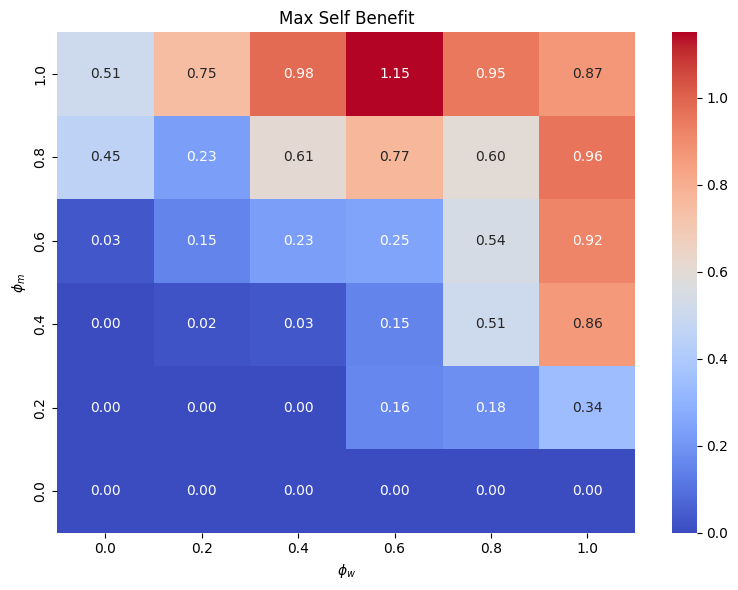

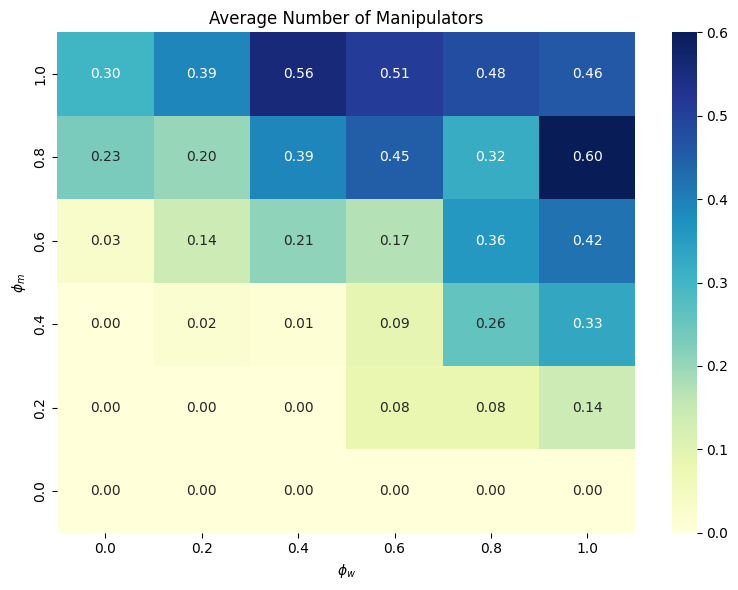

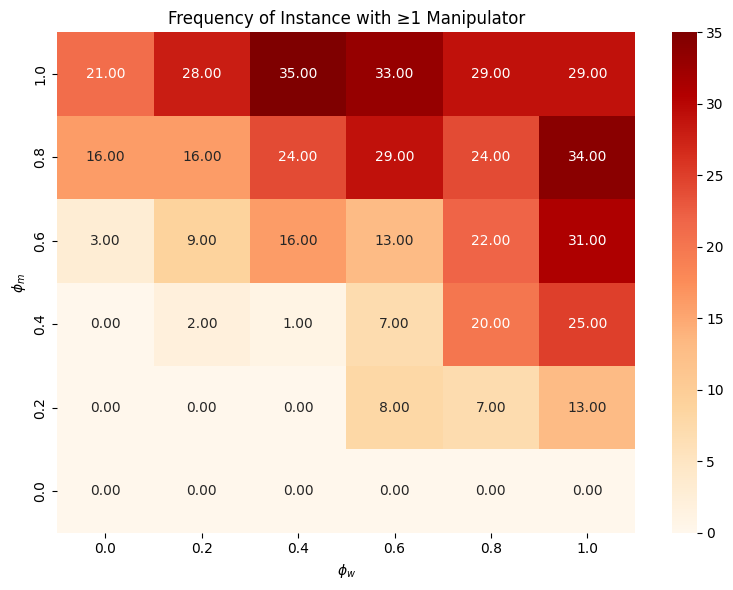

In [11]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import ast  # to convert stringified lists to actual lists

# --- Load your CSV ---
df = pd.read_csv("mallows_MA_gain.csv")

# --- Parse "benefit" column into actual Python lists ---
df["self_benefit_parsed"] = df["benefit"].apply(
    lambda x: ast.literal_eval(x) if isinstance(x, str) else x
)

# --- Compute required new columns ---
# (a) average benefit = sum(list)/10
df["max_self_benefit"] = df["self_benefit_parsed"].apply(
    lambda lst: np.max(lst) if lst else 0
)

# (b) number of manipulators = number of entries > 0
df["num_self_manipulators"] = df["self_benefit_parsed"].apply(
    lambda lst: np.sum(np.array(lst) > 0) if lst else 0
)

# (c) frequency of instance = 1 if any manipulator exists
df["self_freq_instance"] = df["num_self_manipulators"].apply(
    lambda x: 1 if x > 0 else 0
)

# --- Save updated file ---
df.to_csv("mallows_MA_gain.csv", index=False)

# --- Group by phi_m, phi_w and average across 100 samples ---
grouped = df.groupby(["phi_m", "phi_w"]).agg(
    max_benefit=("max_self_benefit", "mean"),
    avg_num_manipulators=("num_self_manipulators", "mean"),
    freq_instance=("self_freq_instance", "sum")
).reset_index()

# --- Heatmap 1: Average Self Benefit ---
plt.figure(figsize=(8,6))
heatmap_matrix = grouped.pivot(index = "phi_m", columns = "phi_w", values = "max_benefit")
sns.heatmap(heatmap_matrix, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Max Self Benefit")
plt.xlabel(r"$\phi_w$")
plt.ylabel(r"$\phi_m$")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig("mallows_MA_gain_max_self_benefit.pdf", format='pdf')
plt.show()

# --- Heatmap 2: Average Number of Manipulators ---
plt.figure(figsize=(8,6))
heatmap_matrix = grouped.pivot(index = "phi_m", columns = "phi_w", values = "avg_num_manipulators")
sns.heatmap(heatmap_matrix, annot=True, fmt=".2f", cmap="YlGnBu")
plt.title("Average Number of Manipulators")
plt.xlabel(r"$\phi_w$")
plt.ylabel(r"$\phi_m$")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig("mallows_MA_gain_self_avg_num_manipulators.pdf", format='pdf')
plt.show()

# --- Heatmap 3: Frequency of Instances with ≥1 Manipulator ---
plt.figure(figsize=(8,6))
heatmap_matrix = grouped.pivot(index = "phi_m", columns = "phi_w", values = "freq_instance")
sns.heatmap(heatmap_matrix, annot=True, fmt=".2f", cmap="OrRd")
plt.title("Frequency of Instance with ≥1 Manipulator")
plt.xlabel(r"$\phi_w$")
plt.ylabel(r"$\phi_m$")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig("mallows_MA_gain_self_freq.pdf", format='pdf')
plt.show()


**Accomplice Manipulation**

In [14]:
from AccompliceManipulation import *

In [15]:
df = pd.read_csv("mallows_MA_gain.csv")

results = []

for idx, row in tqdm(df.iterrows()):
    mpref, wpref = ast.literal_eval(row["preferences"]) 
    mpref = [[int(x) for x in sublist] for sublist in mpref]
    wpref = [[int(x) for x in sublist] for sublist in wpref]

    n = len(mpref)
    #original_matching = df["original matchings"][idx]

    original_matching_raw = df["original matchings"][idx]
    original_matching_list = ast.literal_eval(original_matching_raw)
    original_matching = original_matching_list[0]

    instance_results = []  # store all manipulator-accomplice outcomes for this row

    for manipulator in range(1, n+1):
        manipulator_results = []  # all accomplices for this manipulator

        for accomplice in range(1, n+1):
            func_return = accomplice_manipulation(mpref, wpref, manipulator, accomplice)
            new_matching = func_return[0]
            accomplice_pref_after = func_return[1]

            # --- compute benefit ---
            rk1 = rk2 = 1000
            for i in range(n):
                if original_matching[i] == manipulator:
                    partner1 = i + 1
                if new_matching[i] == manipulator:
                    partner2 = i + 1
            
            w_pref = wpref[manipulator - 1]
            for i in range(n):
                if w_pref[i] == partner1:
                    rk1 = i
                if w_pref[i] == partner2:
                    rk2 = i

            benefit = rk1 - rk2  # improvement (positive = better)

            # store for this accomplice
            manipulator_results.append([
                benefit,
                new_matching,
                accomplice_pref_after,
            ])

        # store for this manipulator
        instance_results.append(manipulator_results)

    # store results for this row
    results.append(instance_results)

#print(results)

# attach to df
df["accomplice_results"] = results
df.to_csv('mallows_MA_gain.csv', index=False)


3600it [00:08, 425.84it/s]


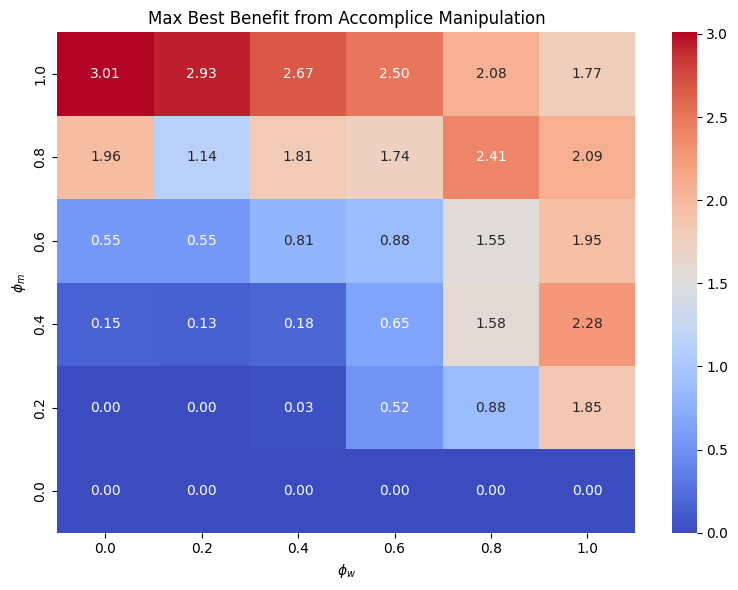

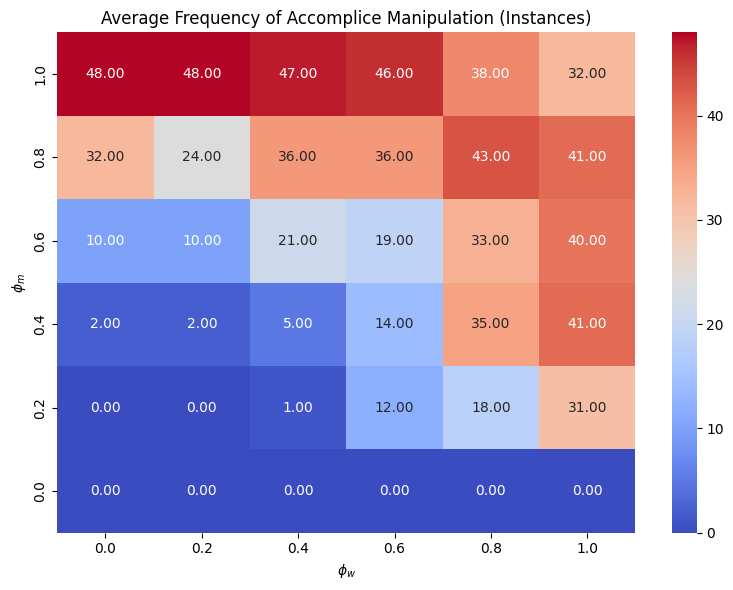

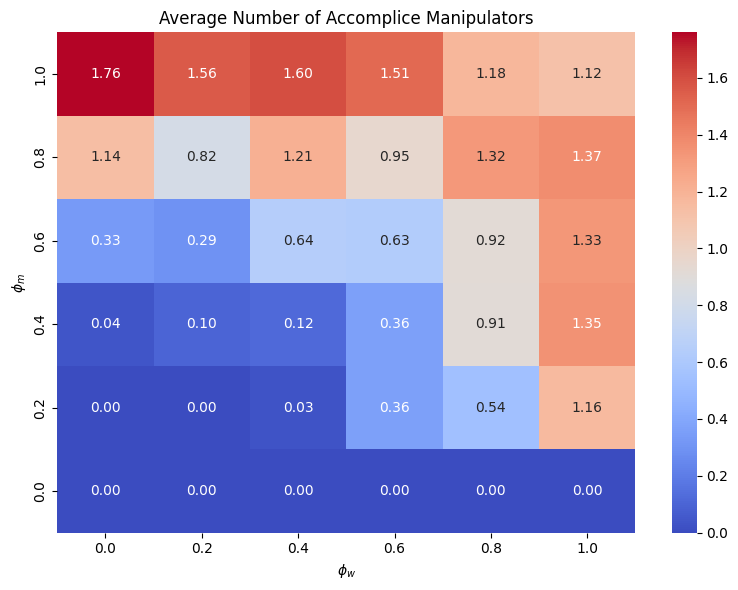

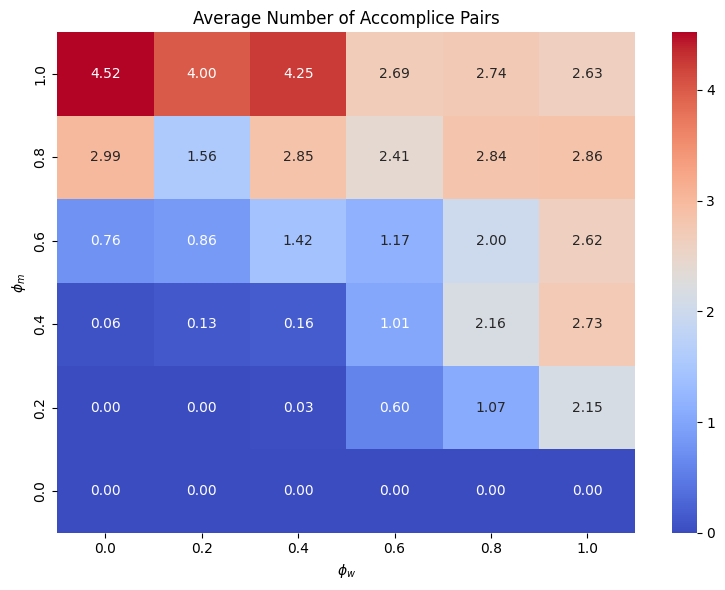

In [16]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import ast  # to convert stringified lists to actual lists

# --- Load your CSV ---
df = pd.read_csv("mallows_MA_gain.csv")  # Uncomment and set filename if needed

# Prepare lists to store the new columns
best_benefits_list = []
max_best_benefit_list = []
acc_freq_instance_list = []
number_acc_pairs_list = []
number_acc_manipulators_list = []

for idx, row in df.iterrows():
    # Convert string to list if needed
    accomplice_results = row["accomplice_results"]
    if isinstance(accomplice_results, str):
        accomplice_results = ast.literal_eval(accomplice_results)

    # Best benefit per manipulator
    best_benefits_per_woman = [
        max(result[0] for result in manipulator_results)
        for manipulator_results in accomplice_results
    ]
    best_benefits_list.append(best_benefits_per_woman)

    # Average across manipulators
    max_val = np.max(best_benefits_per_woman)
    max_best_benefit_list.append(max_val)

    # --- New columns ---
    # 1. acc_freq_instance
    acc_freq_instance_list.append(1 if max_val > 0 else 0)

    # 2. number_acc_pairs: manipulator has accomplice with benefit > 0
    #num_pairs = sum(
        #any(result[0] > 0 for result in manipulator_results)
        #for manipulator_results in accomplice_results
    #)
    #number_acc_pairs_list.append(num_pairs)

    num_pairs = sum(
    sum(1 for result in manipulator_results if result[0] > 0)
    for manipulator_results in accomplice_results
    )
    number_acc_pairs_list.append(num_pairs)

    # 3. number_acc_manipulators: count of >0 best benefits
    num_manipulators = sum(1 for b in best_benefits_per_woman if b > 0)
    number_acc_manipulators_list.append(num_manipulators)

# Add new columns to the original DataFrame
df["best_benefits_per_woman_acc"] = best_benefits_list
df["max_best_benefit_acc"] = max_best_benefit_list
df["acc_freq_instance"] = acc_freq_instance_list
df["number_acc_pairs"] = number_acc_pairs_list
df["number_acc_manipulators"] = number_acc_manipulators_list

# --- Save the updated DataFrame to CSV ---
df.to_csv("mallows_MA_gain.csv", index=False)

# --- Function to plot heatmap for a given column ---
def plot_heatmap(df, value_col, title, filename):
    heatmap_df = df.groupby(["phi_m", "phi_w"])[value_col].mean().reset_index()
    heatmap_matrix = heatmap_df.pivot_table(
        index="phi_m",
        columns="phi_w",
        values=value_col,
        aggfunc="mean"
    )

    plt.figure(figsize=(8, 6))
    sns.heatmap(heatmap_matrix, annot=True, fmt=".2f", cmap="coolwarm")
    plt.title(title)
    plt.xlabel(r'$\phi_w$')
    plt.ylabel(r"$\phi_m$")
    plt.tight_layout()
    plt.gca().invert_yaxis()
    
    plt.savefig(f"{filename}.pdf", format="pdf", bbox_inches="tight")
    plt.show()

def plot_heatmap_sum(df, value_col, title, filename):
    heatmap_df = df.groupby(["phi_m", "phi_w"])[value_col].sum().reset_index()
    heatmap_matrix = heatmap_df.pivot_table(
        index="phi_m",
        columns="phi_w",
        values=value_col,
        aggfunc="sum"
    )

    plt.figure(figsize=(8, 6))
    sns.heatmap(heatmap_matrix, annot=True, fmt=".2f", cmap="coolwarm")
    plt.title(title)
    plt.xlabel(r'$\phi_w$')
    plt.ylabel(r"$\phi_m$")
    plt.tight_layout()
    plt.gca().invert_yaxis()
    
    plt.savefig(f"{filename}.pdf", format="pdf", bbox_inches="tight")
    plt.show()

# --- Generate the 4 plots ---
plot_heatmap(df, "max_best_benefit_acc", "Max Best Benefit from Accomplice Manipulation", "mallows_MA_max_best_benefit_acc")
plot_heatmap_sum(df, "acc_freq_instance", "Average Frequency of Accomplice Manipulation (Instances)", "mallows_MA_acc_freq_instance")
plot_heatmap(df, "number_acc_manipulators", "Average Number of Accomplice Manipulators", "mallows_MA_number_acc_manipulators")
plot_heatmap(df, "number_acc_pairs", "Average Number of Accomplice Pairs", "mallows_MA_number_acc_pairs")


**Two for One**

In [17]:
## Two for One Code

import itertools
import copy

def generate_sw_manipulations(w_pref):
    """
    Sw: Move any two distinct men to top of w's list in any order.
    """
    manipulations = []
    for mi, mj in itertools.permutations(w_pref, 2): 
        rest = [m for m in w_pref if m != mi and m != mj]
        new_pref = [mi, mj] + rest
        manipulations.append(new_pref)
    return manipulations


def generate_sm_manipulations(m_pref, mu_m):
    """
    Sm: Promote µ(m) to top, then for every other woman, promote her to top of that list.
    """
    sm = []
    bm = [mu_m] + [w for w in m_pref if w != mu_m]
    sm.append(bm)

    for w0 in bm[1:]:  # exclude mu(m) which is already at the top
        manipulated = [w0] + [w for w in bm if w != w0]
        sm.append(manipulated)

    return sm


def two_for_one(mpref, wpref, accomplice, beneficiary, initial_matching):
    #initial_matching = gale_shapley(mpref, wpref)
    mpref_prime = copy.deepcopy(mpref)
    wpref_prime = copy.deepcopy(wpref)
    best_matching = initial_matching

    accomplice_pref = mpref[accomplice - 1] 
    beneficiary_pref = wpref[beneficiary - 1]

    Sw = generate_sw_manipulations(beneficiary_pref)

    for w_misreport in Sw:
        #t5 = time.perf_counter()

        Sm = generate_sm_manipulations(accomplice_pref, initial_matching[accomplice - 1])

        for m_misreport in Sm:
            #t6 = time.perf_counter()
            mpref_prime[accomplice - 1] = m_misreport 
            wpref_prime[beneficiary - 1] = w_misreport
            new_matching = gale_shapley(mpref_prime, wpref_prime)

            new_w_pairing = new_matching[beneficiary - 1]
            new_m_pairing = new_matching[accomplice - 1]

            if beneficiary_pref.index(new_w_pairing) < beneficiary_pref.index(best_matching[beneficiary - 1]) and best_matching[accomplice - 1] == new_m_pairing:
                best_matching = new_matching
                accomplice_pref = m_misreport
                beneficiary_pref = w_misreport
        #t7 = time.perf_counter()
        #print(f"Time for t5 - t6: {t6 - t5:.4f} seconds")
        #print(f"Time for t6 - t7: {t7 - t6:.4f} seconds")
    return best_matching, accomplice_pref, beneficiary_pref

In [18]:
df = pd.read_csv("mallows_MA_gain.csv")

results = []

for idx, row in tqdm(df.iterrows()):
    mpref, wpref = ast.literal_eval(row["preferences"]) 
    mpref = [[int(x) for x in sublist] for sublist in mpref]
    wpref = [[int(x) for x in sublist] for sublist in wpref]

    n = len(mpref)
    #original_matching = df["original matchings"][idx]

    original_matching_raw = df["original matchings"][idx]
    original_matching_list = ast.literal_eval(original_matching_raw)
    original_matching = original_matching_list[0]

    instance_results = []  # store all manipulator-accomplice outcomes for this row

    for manipulator in range(1, n+1):
        manipulator_results = []  # all accomplices for this manipulator

        for accomplice in range(1, n+1):
            func_return = two_for_one(mpref, wpref, accomplice, manipulator, original_matching)
            new_matching = func_return[0]
            accomplice_pref_after, beneficiary_pref_after = func_return[1:]

            # --- compute benefit ---
            rk1 = rk2 = 1000
            for i in range(n):
                if original_matching[i] == manipulator:
                    partner1 = i + 1
                if new_matching[i] == manipulator:
                    partner2 = i + 1
            
            w_pref = wpref[manipulator - 1]
            for i in range(n):
                if w_pref[i] == partner1:
                    rk1 = i
                if w_pref[i] == partner2:
                    rk2 = i

            benefit = abs(rk1 - rk2)  # improvement (positive = better)

            # store for this accomplice
            manipulator_results.append([
                benefit,
                new_matching,
                accomplice_pref_after,
                beneficiary_pref_after
            ])

        # store for this manipulator
        instance_results.append(manipulator_results)

    # store results for this row
    results.append(instance_results)

#print(results)

# attach to df
df["two_for_one_results"] = results
df.to_csv('mallows_MA_gain.csv', index=False)


3600it [1:58:50,  1.98s/it] 


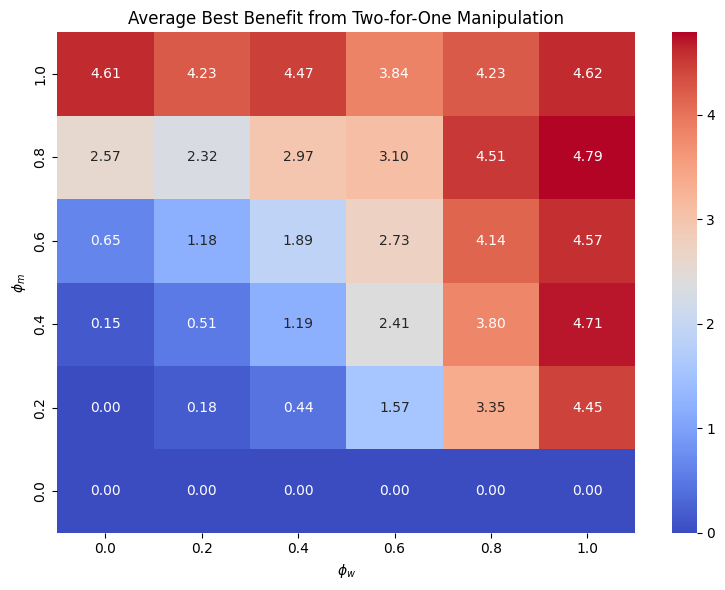

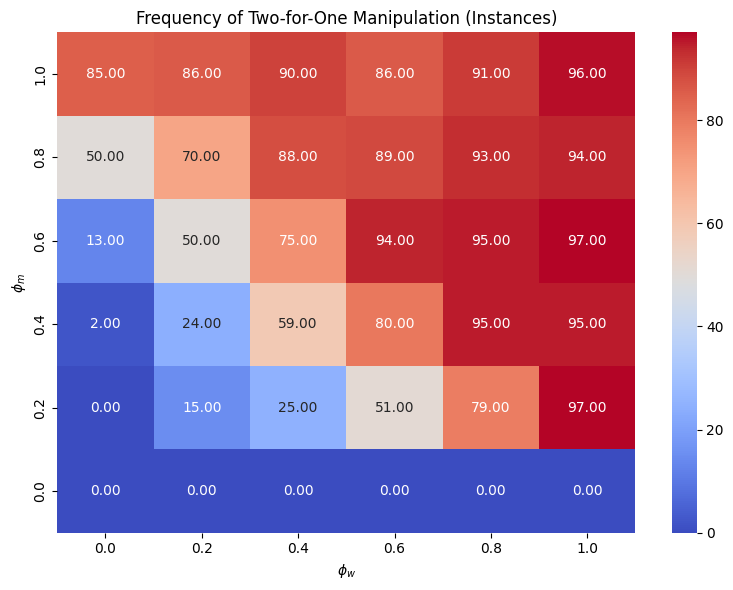

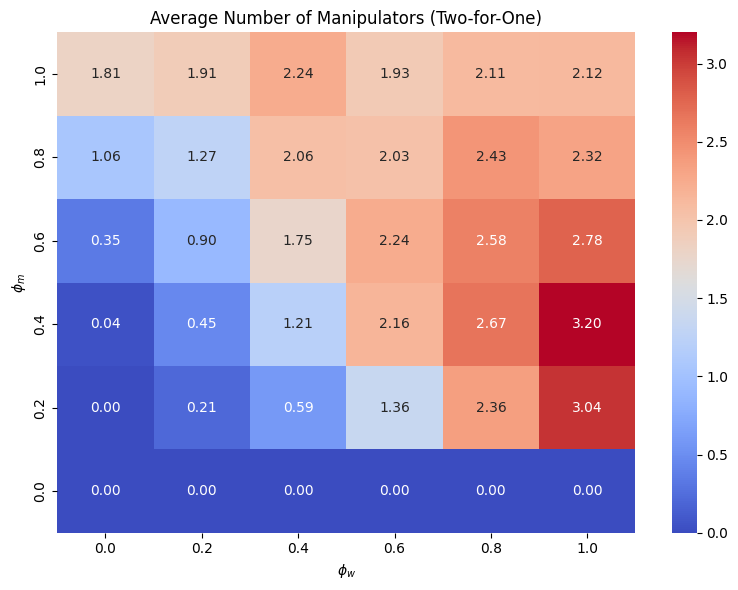

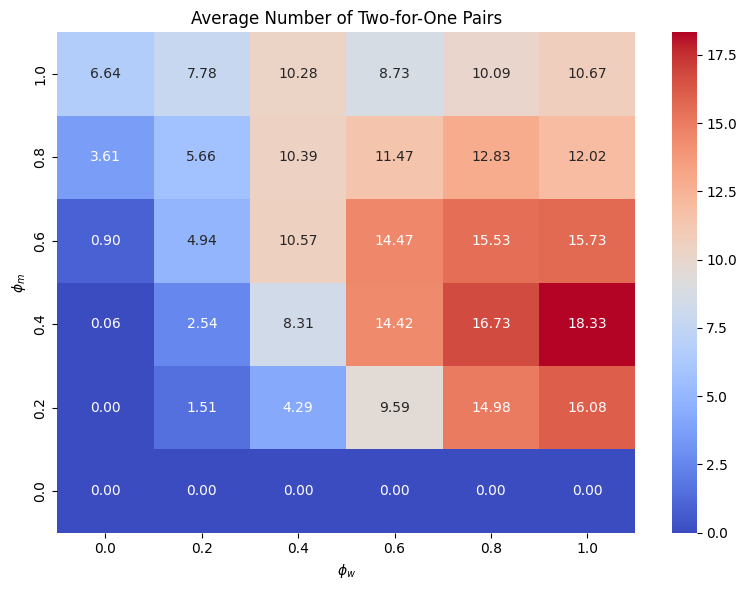

In [19]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import ast  # to convert stringified lists to actual lists

# --- Load your CSV ---
df = pd.read_csv("mallows_MA_gain.csv")

# Prepare lists to store the new columns
best_benefits_list = []
max_best_benefit_list = []
acc_freq_instance_list = []
number_acc_pairs_list = []
number_acc_manipulators_list = []

for idx, row in df.iterrows():
    # Convert string to list if needed
    two_for_one_results = row["two_for_one_results"]
    if isinstance(two_for_one_results, str):
        two_for_one_results = ast.literal_eval(two_for_one_results)

    # Best benefit per manipulator
    best_benefits_per_woman = [
        max(result[0] for result in manipulator_results)
        for manipulator_results in two_for_one_results
    ]
    best_benefits_list.append(best_benefits_per_woman)

    # Average across manipulators
    max_val = np.max(best_benefits_per_woman)
    max_best_benefit_list.append(max_val)

    # --- New columns ---
    acc_freq_instance_list.append(1 if max_val > 0 else 0)

    # number_acc_pairs: manipulator has at least one accomplice with benefit > 0
    #num_pairs = sum(
        #any(result[0] > 0 for result in manipulator_results)
        #for manipulator_results in two_for_one_results
    #)
    #number_acc_pairs_list.append(num_pairs)

    num_pairs = sum(
    sum(1 for result in manipulator_results if result[0] > 0)
    for manipulator_results in two_for_one_results
    )
    number_acc_pairs_list.append(num_pairs)

    # number_acc_manipulators: count of >0 best benefits
    num_manipulators = sum(1 for b in best_benefits_per_woman if b > 0)
    number_acc_manipulators_list.append(num_manipulators)

# Add new columns to the original DataFrame
df["best_benefits_per_woman_two"] = best_benefits_list
df["max_best_benefit_two"] = max_best_benefit_list
df["two_freq_instance"] = acc_freq_instance_list
df["number_two_pairs"] = number_acc_pairs_list
df["number_two_manipulators"] = number_acc_manipulators_list

# --- Save the updated DataFrame to CSV ---
df.to_csv("mallows_MA_gain.csv", index=False)

# --- Function to plot heatmap for a given column ---
def plot_heatmap(df, value_col, title, filename):
    heatmap_df = df.groupby(["phi_m", "phi_w"])[value_col].mean().reset_index()
    heatmap_matrix = heatmap_df.pivot_table(
        index="phi_m",
        columns="phi_w",
        values=value_col,
        aggfunc="mean"
    )

    plt.figure(figsize=(8, 6))
    sns.heatmap(heatmap_matrix, annot=True, fmt=".2f", cmap="coolwarm")
    plt.title(title)
    plt.xlabel(r'$\phi_w$')
    plt.ylabel(r"$\phi_m$")
    plt.tight_layout()
    plt.gca().invert_yaxis()
 
    plt.savefig(f"{filename}.pdf", format="pdf", bbox_inches="tight")
    plt.show()

def plot_heatmap_sum(df, value_col, title, filename):
    heatmap_df = df.groupby(["phi_m", "phi_w"])[value_col].sum().reset_index()
    heatmap_matrix = heatmap_df.pivot_table(
        index="phi_m",
        columns="phi_w",
        values=value_col,
        aggfunc="sum"
    )

    plt.figure(figsize=(8, 6))
    sns.heatmap(heatmap_matrix, annot=True, fmt=".2f", cmap="coolwarm")
    plt.title(title)
    plt.xlabel(r'$\phi_w$')
    plt.ylabel(r"$\phi_m$")
    plt.tight_layout()
    plt.gca().invert_yaxis()

    plt.savefig(f"{filename}.pdf", format="pdf", bbox_inches="tight")
    plt.show()

# --- Generate the 4 plots ---
plot_heatmap(df, "max_best_benefit_two", "Average Best Benefit from Two-for-One Manipulation", "mallows_MA_max_best_benefit_two")
plot_heatmap_sum(df, "two_freq_instance", "Frequency of Two-for-One Manipulation (Instances)", "mallows_MA_two_freq_instance")
plot_heatmap(df, "number_two_manipulators", "Average Number of Manipulators (Two-for-One)", "mallows_MA_number_two_manipulators")
plot_heatmap(df, "number_two_pairs", "Average Number of Two-for-One Pairs", "mallows_MA_number_two_pairs")


**Stability**

In [20]:
from all_stable import *

In [21]:
df = pd.read_csv("mallows_MA_gain.csv")

stability_counts = []

for idx, row in tqdm(df.iterrows()):
    mpref, wpref = ast.literal_eval(row["preferences"]) 
    m_pref = [[int(x) for x in sublist] for sublist in mpref]
    w_pref = [[int(x) for x in sublist] for sublist in wpref]
    mpref = [[int(x)-1 for x in sublist] for sublist in m_pref]
    wpref = [[int(x)-1 for x in sublist] for sublist in w_pref]

    stable = find_all_stable(mpref, wpref, len(mpref))
    num_stable = len(stable)
    stability_counts.append(num_stable)

df["stability_count"] = stability_counts
df.to_csv("mallows_MA_gain.csv", index=False)


3600it [00:00, 3674.68it/s]


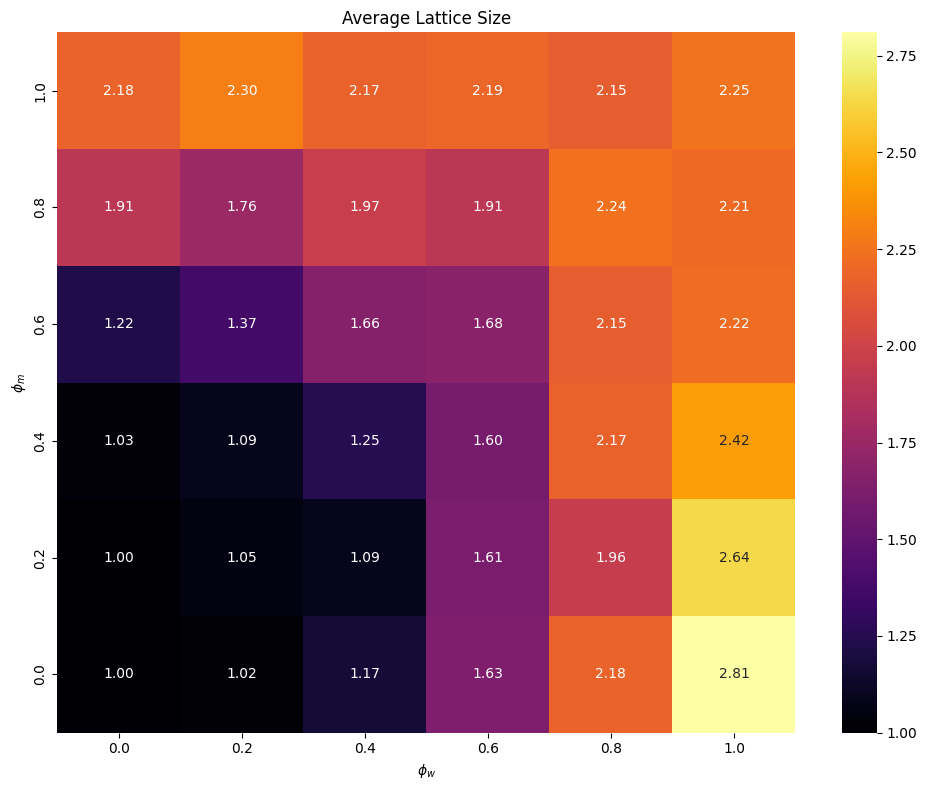

In [22]:

# Load the CSV with stability counts
df = pd.read_csv("mallows_MA_gain.csv")

# Group by phi_m and phi_w and compute the average number of stable matchings
heatmap_data = (
    df.groupby(["phi_m", "phi_w"])["stability_count"]
    .mean()
    .reset_index()
)

# Pivot into matrix form for heatmap
heatmap_matrix = heatmap_data.pivot(index="phi_m", columns="phi_w", values="stability_count")

# Sort the axis values numerically (optional, but often helpful)
heatmap_matrix = heatmap_matrix.sort_index(axis=0).sort_index(axis=1)

# Plot the heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(heatmap_matrix, annot=True, fmt=".2f", cmap="inferno")
plt.title("Average Lattice Size")
plt.xlabel(r"$\phi_w$")
plt.ylabel(r"$\phi_m$")
plt.tight_layout()
plt.gca().invert_yaxis()
plt.savefig("mallows_MA_avg_lattice_size.pdf")
plt.show()


In [58]:
import numpy as np

In [5]:
#Run Gale-Shapley

def gale_shapley(mpref, wpref, strategic_woman=0):
    n = len(mpref)
    curr_match_count = 0
    last_rejected_by_rank_what = [0 for i in range(n)]
    men_matchings = [0 for i in range(n)]
    women_matchings = [0 for i in range(n)]
    proposals_to_strategic_woman = set()    # Only used if strategic_woman != 0

    # continue until all matches made
    while curr_match_count < n:
        for man in range(n):
            # if man is single
            if men_matchings[man] == 0:
                # get first non-rejecting woman from man's preference list
                woman = mpref[man][last_rejected_by_rank_what[man]] - 1
                if woman + 1 == strategic_woman:
                    proposals_to_strategic_woman.add(man + 1)

                # both man and woman are single
                if women_matchings[woman] == 0:
                    # create match (man, woman)
                    men_matchings[man] = woman + 1
                    women_matchings[woman] = man + 1
                    curr_match_count += 1

                # woman is with someone
                else:
                    # find ranks of curr_partner and man given woman's preference list
                    curr_partner = women_matchings[woman]
                    curr_partner_rank = wpref[woman].index(curr_partner)
                    man_rank = wpref[woman].index(man + 1)

                    # woman prefers curr_partner over man
                    if curr_partner_rank < man_rank:
                        last_rejected_by_rank_what[man] = mpref[man].index(woman + 1) + 1

                    # woman prefers man over curr_partner
                    else:
                        men_matchings[curr_partner - 1] = 0
                        last_rejected_by_rank_what[curr_partner - 1] = mpref[curr_partner - 1].index(woman + 1) + 1
                        men_matchings[man] = woman + 1
                        women_matchings[woman] = man + 1

    if strategic_woman != 0:
        return men_matchings, proposals_to_strategic_woman
    else:
        return men_matchings


def get_m_partner(m, matches):
    return matches[m - 1]


def get_w_partner(w, matches):
    return matches.index(w) + 1


def get_m_rank(m, mpref, matches):
    partner = matches[m - 1]
    return mpref[m - 1].index(partner) + 1


def get_w_rank(w, wpref, matches):
    partner = matches.index(w) + 1
    return wpref[w - 1].index(partner) + 1


# Checks if matching1 Pareto-improves matching2 for the set of all women
def pareto_improvement_women(wpref, matching1, matching2):
    n = len(matching1)
    matching1_ranks = [get_w_rank(w, wpref, matching1) for w in range(1, n + 1)]
    matching2_ranks = [get_w_rank(w, wpref, matching2) for w in range(1, n + 1)]
    ranks_difference = [matching2_ranks[i] - matching1_ranks[i] for i in range(n)]
    improvement = False
    for diff in ranks_difference:
        if diff < 0:
            return False
        if diff > 0:
            improvement = True
    return improvement


def check_stability(mpref, wpref, matching, return_blocking_pairs=False):
    n = len(mpref)
    blocking_pairs = []

    for m in range(1, n + 1):
        m_partner = matching[m - 1]
        rank_of_m_partner = mpref[m - 1].index(m_partner) + 1
        for w in range(1, n + 1):
            w_partner = matching.index(w) + 1
            rank_of_w_partner = wpref[w - 1].index(w_partner) + 1

            # if (m, w) is not a matching
            if matching[m - 1] != w:
                rank_of_w_for_m = mpref[m - 1].index(w) + 1
                rank_of_m_for_w = wpref[w - 1].index(m) + 1
                if rank_of_m_partner > rank_of_w_for_m and rank_of_w_partner > rank_of_m_for_w:
                    if return_blocking_pairs:
                        bp = (m, w)
                        blocking_pairs.append(bp)
                    else:
                        return False

    if return_blocking_pairs:
        return blocking_pairs
    else:
        return True



        
def self_manipulation(mpref, wpref, manipulator, return_all_strategies=False):
    n = len(mpref)

    # initial run of gale_shapley
    gs_matching, all_proposers = gale_shapley(mpref, wpref, manipulator)
    #print(gale_shapley(mpref, wpref, manipulator))
    exhausted_proposers = [get_w_partner(manipulator, gs_matching)]

    proposer_dict = {}  # key = proposer; value = manipulated  preference list
    strategy = (gs_matching, wpref[manipulator - 1][:])
    all_strategies = [strategy]

    # update proposer_dict to include all proposers from the initial run
    for proposer in all_proposers:
        proposer_dict.update({proposer: wpref[manipulator - 1][:]})

    # loop until all potential proposers are exhausted
    while len(exhausted_proposers) != len(all_proposers):
        all_proposers_copy = all_proposers.copy()

        # for all proposers that haven't been exhausted
        for proposer in all_proposers:
            if proposer not in exhausted_proposers:
                # create a new manipulated list with proposer in front
                new_list = proposer_dict[proposer]
                new_list.remove(proposer)
                new_list.insert(0, proposer)
                exhausted_proposers.append(proposer)

                # update each non-exhausted proposer's list in proposer_dict
                for prop in proposer_dict:
                    if prop not in exhausted_proposers:
                        proposer_dict.update({proposer: new_list[:]})

                # run gale_shapley using the new manipulated list
                wpref_new = wpref[:]
                wpref_new[manipulator - 1] = new_list
                new_matching, new_proposers = gale_shapley(mpref, wpref_new, manipulator)
                all_proposers_copy = all_proposers_copy.union(new_proposers)
                strategy = (new_matching[:], new_list[:])
                all_strategies.append(strategy)

                # update proposer_dict to include any new proposers
                for prop in all_proposers_copy:
                    if prop not in exhausted_proposers and prop not in proposer_dict:
                        proposer_dict.update({prop: wpref_new[manipulator - 1][:]})

        # update all_proposers
        all_proposers = all_proposers_copy

    if return_all_strategies:
        return all_strategies

    # find cheater's best ranking man from all those who proposed
    best_man_rank = n + 1
    best_strategy = None
    for strategy in all_strategies:
        rank = get_w_rank(manipulator, wpref, strategy[0])
        if rank < best_man_rank:
            best_man_rank = rank
            best_strategy = strategy

    return best_strategy


**Two for One**

/var/folders/w3/z2mywzxs2rb5b6k_0zt2rwbr0000gn/T/ipykernel_41840/2237502037.py:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_filtered['Two_for_one'] = pd.to_numeric(df_filtered['Two_for_one'], errors='coerce')


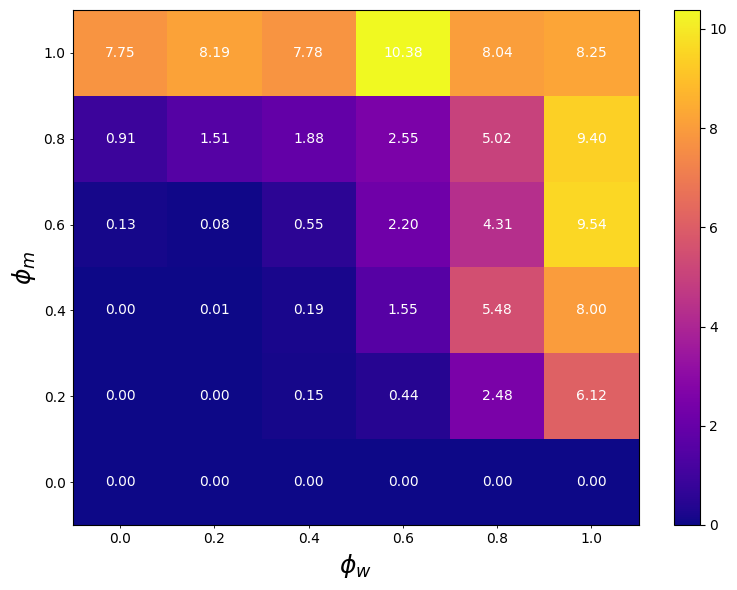

In [ ]:
import pandas as pd #this is for n = 30
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
 
# Load the CSV with headers
df = pd.read_csv("mallows_MA_two_for_one_results(in).csv")
 
# Extract relevant columns: phi1, phi2, and Two_for_one
df_filtered = df[['phim', 'phiw', 'Two_for_one']]
 
# Convert value column to numeric in case there are stray non-numeric entries
df_filtered['Two_for_one'] = pd.to_numeric(df_filtered['Two_for_one'], errors='coerce')
 
# Drop any rows with invalid values
df_filtered = df_filtered.dropna(subset=['Two_for_one'])
 
# Get sorted unique values for heatmap axes
phi1_vals = sorted(df_filtered['phim'].unique())
phi2_vals = sorted(df_filtered['phiw'].unique())
 
# Create pivot table (mean Two_for_one value for each (phi1, phi2) pair)
pivot_table = df_filtered.pivot_table(index='phim', columns='phiw', values='Two_for_one', aggfunc='mean')
 
# Reindex to ensure consistent axis order
pivot_table = pivot_table.reindex(index=phi1_vals, columns=phi2_vals)
 
# Convert to matrix
data_matrix = pivot_table.values
 
# Start plotting
fig, ax = plt.subplots(figsize=(8, 6))
 
# Create the heatmap
c = ax.pcolormesh(data_matrix, cmap='plasma', norm=mcolors.Normalize(vmin=np.nanmin(data_matrix), vmax=np.nanmax(data_matrix)))
 
# Add color bar
fig.colorbar(c, ax=ax)
 
# Annotate each cell
for i in range(data_matrix.shape[0]):
    for j in range(data_matrix.shape[1]):
        val = data_matrix[i, j]
        if not np.isnan(val):
            ax.text(j + 0.5, i + 0.5, f'{val:.2f}', ha='center', va='center', color='white')
 
# Tick positions and labels
ax.set_xticks(np.arange(len(phi2_vals)) + 0.5, minor=True)
ax.set_yticks(np.arange(len(phi1_vals)) + 0.5, minor=True)
ax.set_xticklabels([f'{v:.1f}' for v in phi2_vals], minor=True)
ax.set_yticklabels([f'{v:.1f}' for v in phi1_vals], minor=True)
 
# Hide major ticks
ax.set_xticks([])
ax.set_yticks([])
 
# Show minor ticks only
ax.tick_params(axis='x', which='minor', bottom=True)
ax.tick_params(axis='y', which='minor', left=True)
 
# Labels and title
plt.xlabel(r'$\phi_w$', fontsize=18)
plt.ylabel(r'$\phi_m$', fontsize=18)
#plt.title('Two for One', fontsize=16)
 
# Layout and save
plt.grid(True)
plt.tight_layout()
#plt.savefig("number_of_euclidean_mallows_pairs_two_for_one.pdf", format='pdf')
plt.show()